# Chapter 1 — Adaptive Robust Beamforming: simulation notebook

Reproduces every simulation figure of Chapter 1 (Figs. 1.5–1.27) in Python. The chapter consolidates two papers:

* **TAP 2006** — A. Elnashar, S. M. Elnoubi, H. A. El-Mikati, "Further study on robust adaptive beamforming with optimum diagonal loading," *IEEE Trans. Antennas Propag.*, vol. 54, no. 12, pp. 3647–3658, Dec. 2006. Ellipsoidal (variable-loading) constraint, steepest-descent and conjugate-gradient implementations, joint quadratic constraint. Figs. 1.5–1.16.
* **IET 2008** — A. Elnashar, "On efficient implementation of robust adaptive beamforming based on worst-case performance optimization," *IET Signal Process.*, vol. 2, no. 4, pp. 381–393, Dec. 2008. Adaptive worst-case (WC) MVDR, the ζ-reduction rule, multiple-beam WC (MBWC) LCMV. Figs. 1.17–1.27.

The code is a port of the author's MATLAB scripts with the bug fixes listed below. Running all cells at full Monte Carlo counts takes about 45 minutes on one CPU core; set `QUICK = True` in the configuration cell for a two-minute smoke test.

**Display smoothing.** SINR-vs-snapshot curves are plotted after a centred moving average whose half-width grows as k/4 up to 50 snapshots (one-sided near the last snapshot), so the start-up transient is kept while the steady-state ripple is averaged out (the MATLAB scripts used a zero-phase Butterworth filter, Wn = 0.01, which also smeared the transient). The MSE curves keep the MATLAB filter. Sweep figures are not filtered; they use more Monte Carlo runs instead. All numbers in `results_summary.json` and in the text come from the unsmoothed Monte Carlo means.

**Outputs:** PNG (300 dpi) and PDF of every figure in `../figures/`, and `../figures/results_summary.json` with the steady-state numbers quoted in the text.

**Code:** the algorithms are in `ch1rab/algorithms.py`, the Monte Carlo scenario runners in `ch1rab/scenarios.py`, and the plotting helpers and figure functions in `ch1rab/figures.py`. The figure functions are repeated in the cells below so each figure can be read next to its output; `scripts/generate_figures.py` runs the same functions without Jupyter.

## MATLAB script → figure map

| Chapter figure | Content | MATLAB source | Function below |
|---|---|---|---|
| 1.5, 1.6, 1.7 | SINR, MSE, SOI power vs snapshot, scenario 1 | `RAB4.m`, `RAB_Joint.m` | `fig_1_5_9` |
| 1.8, 1.9 | Beampatterns, scenario 1 | `RAB4.m` | `fig_1_5_9` |
| 1.10 | SINR vs snapshot, scenario 2 (CG) | `RAB5.m`, `RAB_Joint1.m` | `fig_1_10` |
| 1.11, 1.12 | SINR vs noise power, 0.03π and 0.06π mismatch | `RAB6.m`, `RAB_Joint_SNR.m` | `fig_1_11_12` |
| 1.13–1.15 | Moving jammers (non-coherent, coherent, non-stationary) | `RAB_move.m`, `RAB7_Move*.m`, `RAB7_S_Move.m` | `fig_1_13_15` |
| 1.16 | SINR vs mismatch angle | `RAB_Mismatch.m` | `fig_1_16` |
| 1.17, 1.18 | WC: SINR vs snapshot, beampatterns | `RAB_WC3.m` | `fig_1_17`, `fig_1_18` |
| 1.19 | WC: SINR vs noise, N = 50 | `RAB_WC_SNR2.m` | `fig_1_19` |
| 1.20, 1.22, 1.23 | WC parameters A, B, C, λ at ζ = 1.8, 1.2, 2.4 | `RAB_WC3.m` | `fig_1_20_22_23` |
| 1.21 | Effect of ζ on SINR | `RAB_WC3.m` (ζ swept) | `fig_1_21` |
| 1.24, 1.25 | Modified algorithm (ζ-reduction), ζ₀ = 3 | `RAB_WC_epsc.m` | `fig_1_24_25` |
| 1.26 | Small angular spread (local scattering) | `RAB_WC_local2.m` | `fig_1_26` |
| 1.27 | Large angular spread, MBWC | `RAB_WC_LAS.m`, `RAB_WCg4ok.m`, `wcg.m` | `fig_1_27` |

Helpers ported: `SINRF.m` → `sinr_single`, `SINRFm.m` → replaced by `sinr_coherent` (fix 3), `newton1.m` → `newton1`, `newton2.m` → `wc_eig` (fix 5), `NOOjacom.m` → `noojacom`, `robustbeam.m` → `WCSOCP` (fixes 1, 2).

## Fixes relative to the MATLAB code

```text
1. SOCP objective: robustbeam.m factorized chol(real(Rss)), i.e. it optimized w^H Re(R) w.
   The port uses the full complex covariance.
2. SOCP normalization: robustbeam.m was called with as = M*a/||a|| (||as|| = M, not sqrt(M)),
   which silently rescales the uncertainty radius by sqrt(M). The port uses the presumed
   steering vector itself; the radius is then directly comparable with the other methods.
3. Multipath SINR: scripts mixed SINRF (main ray only) and SINRFm (ray powers added
   incoherently). All rays carry the same symbol, so the port scores every beamformer with
   the coherent SINR  P_s |w^H a_eff|^2 / (w^H R_{i+n} w).
4. LCMV benchmarks used pinv(real(C^H R^-1 C)); the port uses the complex matrix.
5. WC eigendecomposition beamformer: newton2.m used a damped (x0.01) Newton step that can stop
   before the root; the port solves sum |z_m|^2/(zeta + t*gamma_m)^2 = 1 exactly (brentq).
6. WC adaptive root: MATLAB could return a complex lambda (sqrt of a negative discriminant).
   The port keeps the smallest real nonnegative root that satisfies the unsquared constraint
   (1.97). If zeta >= ||a|| the WC problem is infeasible and the previous weight is kept. For a
   feasible zeta with no real root it takes the vertex lambda = -B/A (the real part of the complex
   root MATLAB returned) when that is positive; otherwise it keeps the previous weight. If the
   zeta-reduction rule is enabled, zeta is lowered and A, B, C recomputed within the same snapshot.
7. VL quadratic: guards for a = 0 (first snapshot) and a negative discriminant (MATLAB took
   real(sqrt(.)) = 0, i.e. the vertex of the parabola; the port does the same, explicitly).
8. Beam patterns are |w^H a(theta)|^2 normalised to their maximum (MATLAB plotted an SINR-like
   quantity through SINRF).
9. SOI power: Li-Stoica estimate with the steering vector rescaled to norm sqrt(M) and the
   covariance normalised by the number of snapshots, so the curves are comparable with the
   true SOI power instead of growing with k.
10. Display smoothing: the scripts passed every curve through a zero-phase 1st-order Butterworth
   filter (Wn = 0.01) before plotting, including the sweep figures (1.11, 1.12, 1.16, 1.19), where
   it ran across the 16-26 sweep points and bent each curve towards a straight line (e.g. +3 dB
   output SINR at +30 dB noise in Fig. 1.11, where M = 5 allows at most -23 dB). The port plots
   unsmoothed Monte Carlo means; only the MSE curves (Fig. 1.6) keep the snapshot-axis smoothing.
```

**Uncertainty radius of the SOCP beamformer.** With fix 2, the SOCP beamformer and the batch robust Capon beamformer solve the same problem when they use the same radius (Li–Stoica equivalence), so the default `SOCP_RADIUS = 'matched'` gives SOCP the radius √ε of the RCB sphere (TAP part) and ζ (IET part). `SOCP_RADIUS = 'original'` reproduces the radius the MATLAB scripts effectively used (δ/√M, i.e. 1.5/√5, 2/√5 and 3/√5), for comparison with the published figures.

**Text and code disagreements found during the port** (the notebook follows the text where the two differ, except where noted):

* WC interferers: the code and the published figures use 30° and 60°; the text says 45° and 60°. The notebook uses 30°/60°.
* Forgetting factor: the text says η = 0.97; every script uses η = 1 (no forgetting). The notebook uses η = 1.
* Fig. 1.19: the code used N = 100 and 0.02π mismatch; the text says N = 50 and 5°. The notebook follows the text.
* WC mismatch: the scripts used 0.03π (5.4°); the text says 5°. The notebook uses 5°.
* Step size: Table 1.4 gives α = 0.1; `RAB_WC3.m` used 0.01. The notebook uses 0.1.
* Moving-jammer scripts re-solved the SOCP every 100 snapshots; the notebook re-solves it every 10 snapshots, as in all other scenarios.

## Configuration

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath('..'))   # repository root, so `ch1rab` imports without installation
QUICK = False              # True: 3/3/2 Monte Carlo runs instead of 50/100/50 (smoke test)
SOCP_RADIUS = 'matched'    # 'matched' (same radius as RCB / WC) or 'original' (radius the MATLAB scripts used)
FIGDIR = '../figures'   # relative to notebooks/

os.environ['QUICK'] = '1' if QUICK else '0'
os.environ['SOCP_RADIUS'] = SOCP_RADIUS
os.environ['FIGDIR'] = FIGDIR
os.environ['RAB_INLINE'] = '1'
import numpy, scipy, cvxpy, matplotlib
print('numpy', numpy.__version__, '| scipy', scipy.__version__, '| cvxpy', cvxpy.__version__,
      '| matplotlib', matplotlib.__version__)

numpy 2.5.3 | scipy 1.18.1 | cvxpy 1.9.3 | matplotlib 3.11.2


## Library

`ch1rab.algorithms` holds the beamformers (variable-loading RCB, joint constraint, batch and subspace-tracking RCB, WC SOCP, WC eigendecomposition, adaptive WC MVDR with the ζ-reduction rule, MBWC LCMV), `ch1rab.scenarios` the TAP 2006 and IET 2008 scenario runners, and `ch1rab.figures` the plotting helpers. The import below reads the configuration set above.

In [4]:
from ch1rab.figures import *          # helpers, scenario runners, RESULTS
from ch1rab.algorithms import FIXES
print('runs: TAP', RUNS_TAP, '| IET', RUNS_IET, '| sweeps', RUNS_SWEEP, '| SOCP radius:', SOCP_RADIUS)

runs: TAP 50 | IET 100 | sweeps 50 | SOCP radius: matched


## Part A — TAP 2006
### Figs. 1.5–1.9: scenario 1

M = 5 half-wavelength ULA. SOI at 0° (0 dB), presumed at 0.03π; two jammers at 45° and 30° with INR 10 dB; noise −50 dB; ε = 0.5; steepest-descent update with α = 0.008; joint-constraint τ = 0.2; 50 runs, N = 1000. The MSE curve is smoothed with the same zero-phase first-order Butterworth filter (Wn = 0.01) the MATLAB scripts applied before plotting. The beampatterns (Figs. 1.8, 1.9) are from two single runs. A diagnostic records how often the ellipsoidal constraint is active for three step sizes.

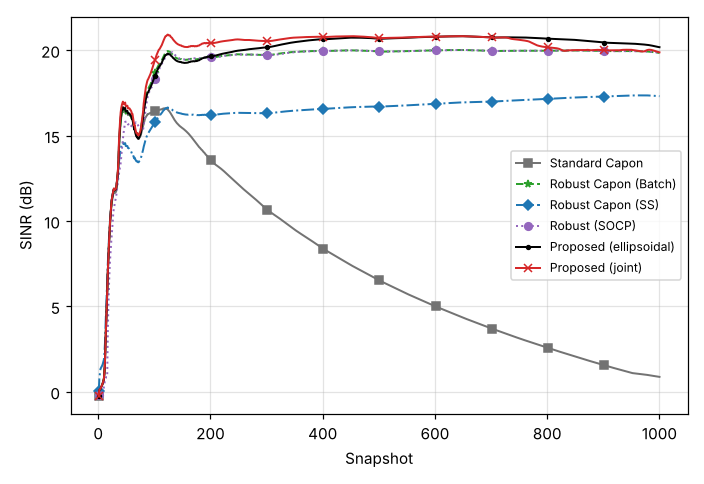

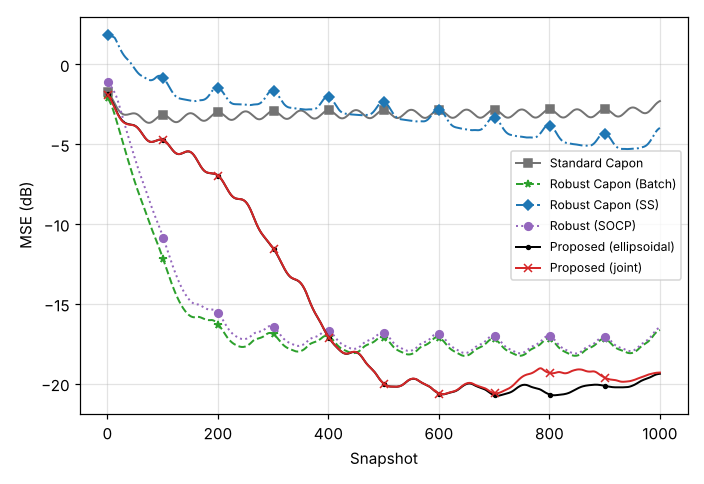

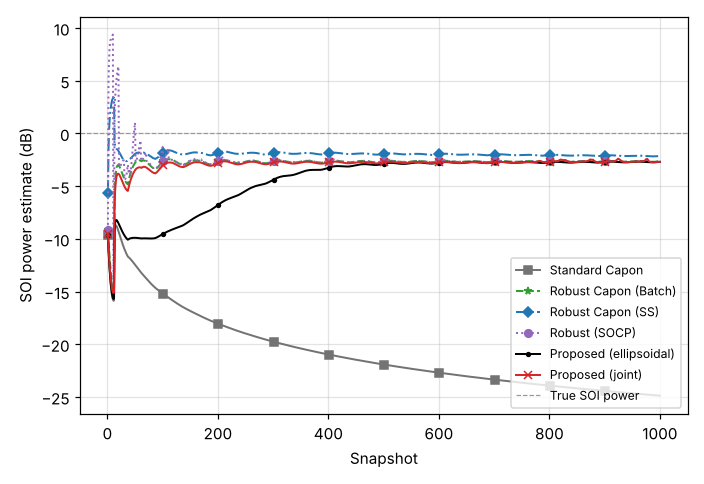

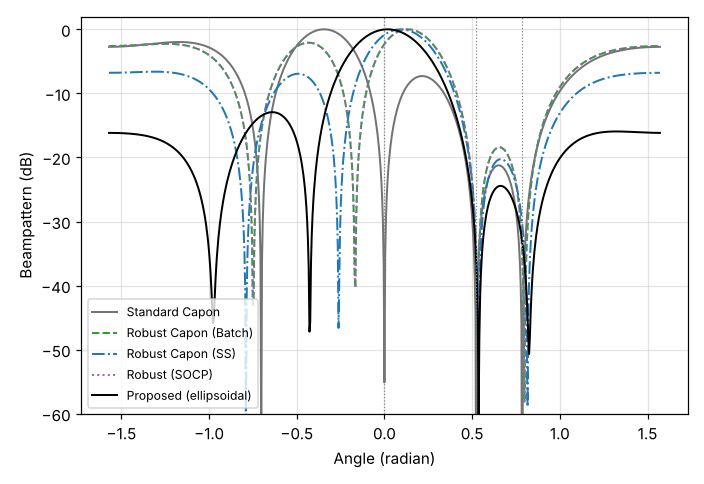

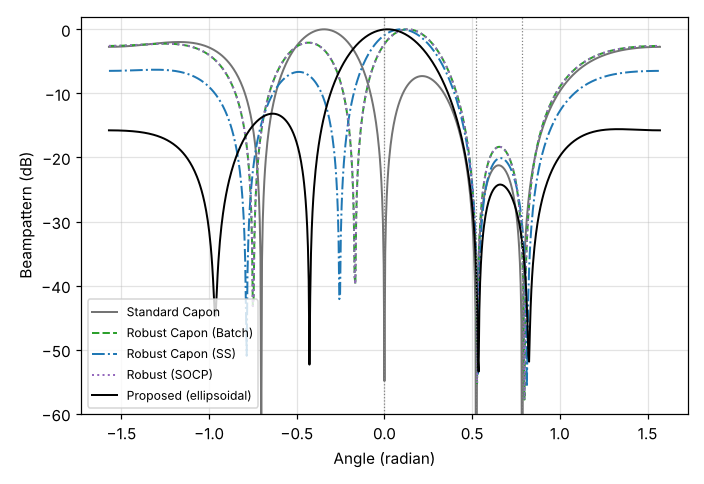

Fig1.5 {
 "Standard Capon": 1.0988567842701746,
 "Robust Capon (Batch)": 19.95451646893592,
 "Robust Capon (SS)": 17.355642222881716,
 "Robust (SOCP)": 19.954537909025877,
 "Proposed1": 20.38675098868181,
 "Proposed2": 20.021079849792898
}
Fig1.6 {
 "Standard Capon": -3.0567340391324613,
 "Robust Capon (Batch)": -17.80195807188687,
 "Robust Capon (SS)": -5.255887143347611,
 "Robust (SOCP)": -17.677715840614198,
 "Proposed1": -20.04968956373034,
 "Proposed2": -19.82658765428626
}
Fig1.7 {
 "Standard Capon": -24.65398628852537,
 "Robust Capon (Batch)": -2.650810569228415,
 "Robust Capon (SS)": -2.120949272989362,
 "Robust (SOCP)": -2.6490486216137707,
 "Proposed1": -2.7041880756039545,
 "Proposed2": -2.644345619215796
}
diag_VL_activity_scenario1 {
 "alpha=0.008": {
  "VL activations": 0,
  "final SINR dB": 21.45
 },
 "alpha=0.02": {
  "VL activations": 842,
  "final SINR dB": 20.8
 },
 "alpha=0.05": {
  "VL activations": 992,
  "final SINR dB": 20.93
 }
}


In [5]:
def fig_1_5_9():
    """Scenario 1: Figs 1.5-1.9 (SD, 0.03pi, eps 0.5, noise -50 dB)"""
    sc1 = dict(noise_db=-50, mis=0.03 * np.pi, eps=0.5, delta_socp=socp_delta(0.5, 1.5), alpha=0.008,
               method='SD', tau=0.2)
    acc = tap_mc(RUNS_TAP, base_seed=0, **sc1)
    fig, _ = curve_plot({m: db(msmooth(acc[m]['sinr'])) for m in TAP_METHODS}, 'SINR (dB)', '')
    save(fig, 'Fig1_05_SINR_scenario1')
    fig, _ = curve_plot({m: db(smooth(acc[m]['mse'])) for m in TAP_METHODS}, 'MSE (dB)', '')
    save(fig, 'Fig1_06_MSE_scenario1')
    fig, _ = curve_plot({m: db(acc[m]['soip']) for m in TAP_METHODS}, 'SOI power estimate (dB)', '',
                        ref=(0.0, 'True SOI power'))
    save(fig, 'Fig1_07_SOIP_scenario1')
    RESULTS['Fig1.5'] = {m: ss(acc[m]['sinr']) for m in TAP_METHODS}
    RESULTS['Fig1.6'] = {m: ss(acc[m]['mse']) for m in TAP_METHODS}
    RESULTS['Fig1.7'] = {m: ss(acc[m]['soip']) for m in TAP_METHODS}
    keep = KEEP_A
    marks = [0.0, np.pi / 6, np.pi / 4]
    for j, (seed, name) in enumerate([(0, 'Fig1_08_beampattern_a'), (1, 'Fig1_09_beampattern_b')]):
        o = tap_run(seed, **sc1)
        pattern_plot({m: o['_w'][m] for m in keep}, name, marks)
    # diagnostic: is the ellipsoidal constraint ever active?
    diag = {}
    for al in (0.008, 0.02, 0.05):
        o = tap_run(0, **dict(sc1, alpha=al))
        diag[al] = (o['_vl_count'], float(db(o['Proposed1']['sinr'][-1])))
    RESULTS['diag_VL_activity_scenario1'] = {f'alpha={k}': {'VL activations': v[0], 'final SINR dB': round(v[1], 2)}
                                             for k, v in diag.items()}


fig_1_5_9()
import json
for _k in ['Fig1.5', 'Fig1.6', 'Fig1.7', 'diag_VL_activity_scenario1']:
    if _k in RESULTS:
        print(_k, json.dumps(RESULTS[_k], indent=1, default=str))

### Fig. 1.10: scenario 2

Mismatch 0.06π, ε = 1, noise −20 dB, conjugate-gradient (Polak–Ribière) update with α = 0.01.

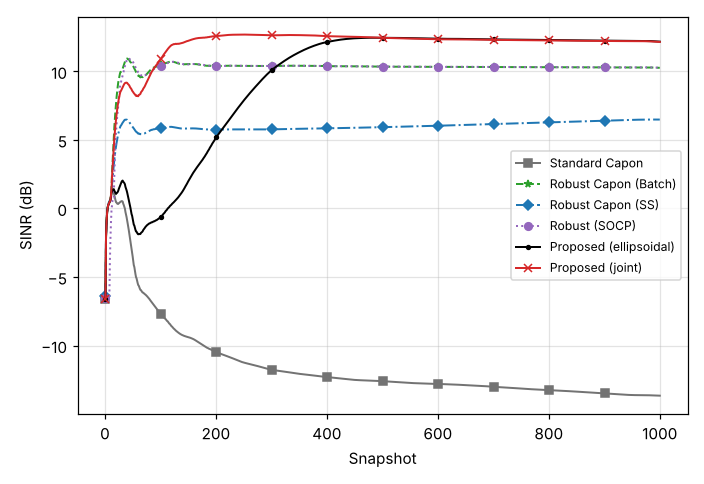

Fig1.10 {
 "Standard Capon": -13.611174596788045,
 "Robust Capon (Batch)": 10.291775003567272,
 "Robust Capon (SS)": 6.467850104662918,
 "Robust (SOCP)": 10.292265195209414,
 "Proposed1": 12.23075053646036,
 "Proposed2": 12.20683880646357
}
diag_VL_activity_scenario2 {
 "VL activations (one run)": 0
}


In [6]:
def fig_1_10():
    """Scenario 2: Fig 1.10 (CG, 0.06pi, eps 1, noise -20 dB)"""
    sc2 = dict(noise_db=-20, mis=0.06 * np.pi, eps=1.0, delta_socp=socp_delta(1.0, 2.0), alpha=0.01,
               method='CG', tau=0.2)
    acc = tap_mc(RUNS_TAP, base_seed=100, **sc2)
    fig, _ = curve_plot({m: db(msmooth(acc[m]['sinr'])) for m in TAP_METHODS}, 'SINR (dB)', '')
    save(fig, 'Fig1_10_SINR_scenario2')
    RESULTS['Fig1.10'] = {m: ss(acc[m]['sinr']) for m in TAP_METHODS}
    o = tap_run(100, **sc2)
    RESULTS['diag_VL_activity_scenario2'] = {'VL activations (one run)': o['_vl_count']}


fig_1_10()
import json
for _k in ['Fig1.10', 'diag_VL_activity_scenario2']:
    if _k in RESULTS:
        print(_k, json.dumps(RESULTS[_k], indent=1, default=str))

### Figs. 1.11, 1.12: SINR vs noise power

Final-snapshot SINR (N = 1000) for noise from +30 dB to −30 dB, ε = 1, 50 runs per point; 0.03π mismatch (Fig. 1.11) and 0.06π mismatch (Fig. 1.12).

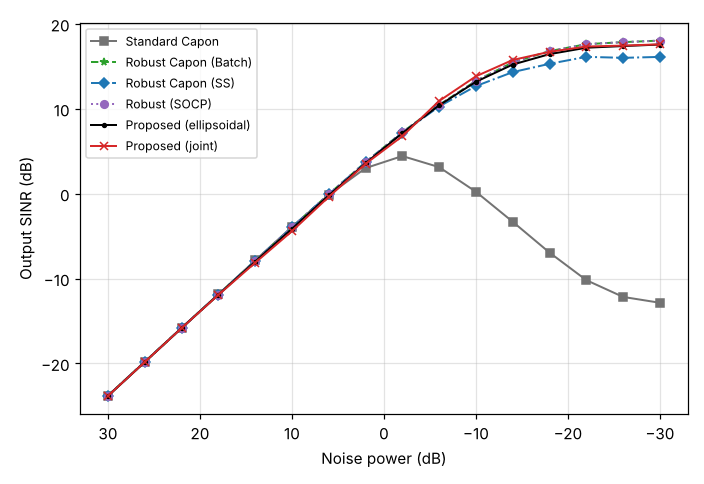

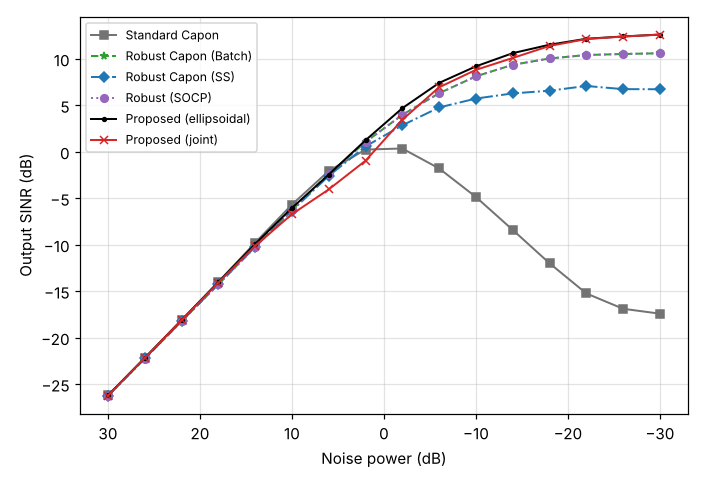

Fig1.11 {
 "Standard Capon": {
  "30": -23.8,
  "18": -11.85,
  "6": -0.14,
  "-6": 3.13,
  "-18": -6.93,
  "-30": -12.85
 },
 "Robust Capon (Batch)": {
  "30": -23.8,
  "18": -11.88,
  "6": -0.05,
  "-6": 10.45,
  "-18": 16.8,
  "-30": 18.04
 },
 "Robust Capon (SS)": {
  "30": -23.8,
  "18": -11.87,
  "6": -0.06,
  "-6": 10.27,
  "-18": 15.31,
  "-30": 16.12
 },
 "Robust (SOCP)": {
  "30": -23.8,
  "18": -11.88,
  "6": -0.05,
  "-6": 10.45,
  "-18": 16.8,
  "-30": 18.04
 },
 "Proposed1": {
  "30": -23.82,
  "18": -11.9,
  "6": -0.2,
  "-6": 10.41,
  "-18": 16.44,
  "-30": 17.58
 },
 "Proposed2": {
  "30": -23.82,
  "18": -11.92,
  "6": -0.37,
  "-6": 10.92,
  "-18": 16.72,
  "-30": 17.6
 }
}
Fig1.12 {
 "Standard Capon": {
  "30": -26.2,
  "18": -14.01,
  "6": -2.08,
  "-6": -1.8,
  "-18": -12.0,
  "-30": -17.42
 },
 "Robust Capon (Batch)": {
  "30": -26.25,
  "18": -14.26,
  "6": -2.42,
  "-6": 6.29,
  "-18": 10.03,
  "-30": 10.59
 },
 "Robust Capon (SS)": {
  "30": -26.24,
  "18": -1

In [7]:
def fig_1_11_12():
    """Figs 1.11, 1.12: SINR vs noise power (final snapshot, N = 1000)"""
    noise = np.arange(30, -31, -4)
    for name, mis, al, key in [('Fig1_11_SINR_vs_noise_003pi', 0.03 * np.pi, 0.02, 'Fig1.11'),
                               ('Fig1_12_SINR_vs_noise_006pi', 0.06 * np.pi, 0.008, 'Fig1.12')]:
        res = {m: np.zeros(len(noise)) for m in TAP_METHODS}
        for i, nd in enumerate(noise):
            for r in range(RUNS_SWEEP):
                o = tap_run(500 + 37 * i + r, noise_db=nd, mis=mis, eps=1.0, delta_socp=socp_delta(1.0, 2.0),
                            alpha=al, method='SD', tau=0.2, final_only=True)
                for m in TAP_METHODS:
                    res[m][i] += o[m]['sinr'][-1] / RUNS_SWEEP
        fig, ax = curve_plot({m: db(res[m]) for m in TAP_METHODS}, 'Output SINR (dB)', '',
                             xlabel='Noise power (dB)', x=noise)
        ax.invert_xaxis()
        save(fig, name)
        RESULTS[key] = {m: dict(zip([int(v) for v in noise[::3]], np.round(db(res[m])[::3], 2).tolist()))
                        for m in TAP_METHODS}


fig_1_11_12()
import json
for _k in ['Fig1.11', 'Fig1.12']:
    if _k in RESULTS:
        print(_k, json.dumps(RESULTS[_k], indent=1, default=str))

### Figs. 1.13–1.15: moving jammers

Noise −20 dB, mismatch 0.01π, ε = 0.5, α = 0.01. Trajectories (1.116)–(1.119): both jammers drift in the same direction (non-coherent), in opposite directions (coherent), or oscillate as 10° sin(k/15) (non-stationary).

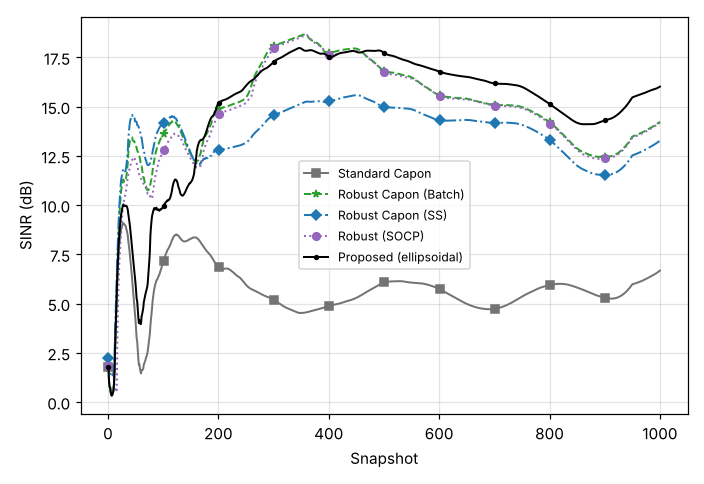

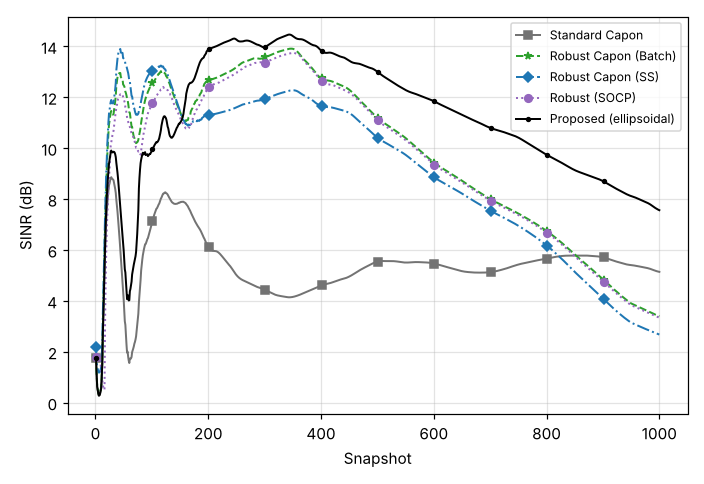

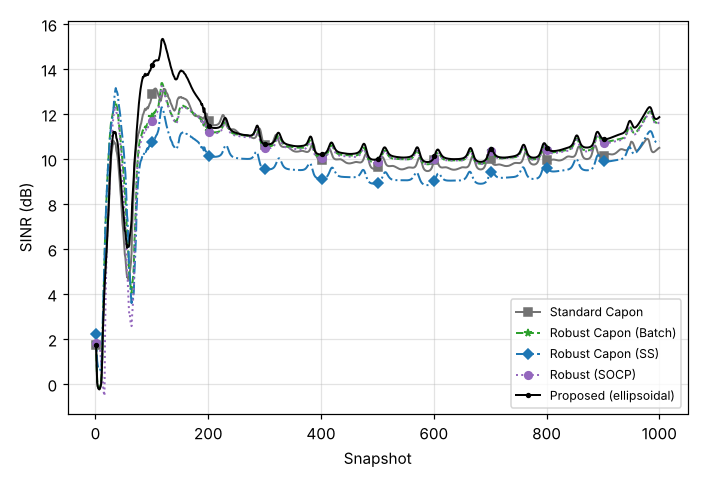

Fig1.13 {
 "Standard Capon": 5.985550542904418,
 "Robust Capon (Batch)": 13.484913205422224,
 "Robust Capon (SS)": 12.529689552228243,
 "Robust (SOCP)": 13.426710377310474,
 "Proposed1": 15.477188078782138
}
Fig1.14 {
 "Standard Capon": 5.405898972439044,
 "Robust Capon (Batch)": 3.891407401797644,
 "Robust Capon (SS)": 3.1349960219425093,
 "Robust (SOCP)": 3.825053408224053,
 "Proposed1": 8.110718329912443
}
Fig1.15 {
 "Standard Capon": 10.767086294892824,
 "Robust Capon (Batch)": 11.311941894029191,
 "Robust Capon (SS)": 10.358407397679954,
 "Robust (SOCP)": 11.256663462895329,
 "Proposed1": 11.58025840032037
}


In [8]:
def fig_1_13_15():
    """Figs 1.13-1.15: moving jammers (noise -20 dB, 0.01pi mismatch, joint excluded)"""
    d2r = np.pi / 180
    moving = [('Fig1_13_moving_noncoherent', lambda k: (np.pi / 4 + 0.1 * d2r * k, np.pi / 6 + 0.01 * d2r * k)),
              ('Fig1_14_moving_coherent', lambda k: (np.pi / 4 + 0.1 * d2r * k, np.pi / 6 - 0.01 * d2r * k)),
              ('Fig1_15_moving_nonstationary', lambda k: (np.pi / 4 + 10 * d2r * np.sin(k / 15),
                                                          np.pi / 6 + 10 * d2r * np.sin(k / 15)))]
    keep = KEEP_A
    for j, (name, traj) in enumerate(moving):
        acc = tap_mc(RUNS_TAP, base_seed=200 + 100 * j, noise_db=-20, mis=0.01 * np.pi, eps=0.5,
                     delta_socp=socp_delta(0.5, 1.5), alpha=0.01, method='SD', tau=None, traj=traj)
        fig, _ = curve_plot({m: db(msmooth(acc[m]['sinr'])) for m in keep}, 'SINR (dB)', '')
        save(fig, name)
        RESULTS['Fig1.' + name[5:7]] = {m: ss(acc[m]['sinr']) for m in keep}


fig_1_13_15()
import json
for _k in ['Fig1.13', 'Fig1.14', 'Fig1.15']:
    if _k in RESULTS:
        print(_k, json.dumps(RESULTS[_k], indent=1, default=str))

### Fig. 1.16: SINR vs mismatch angle

Mismatch 0°–20°, noise −15 dB, ε = 1, final snapshot of N = 1000, 50 runs per point.

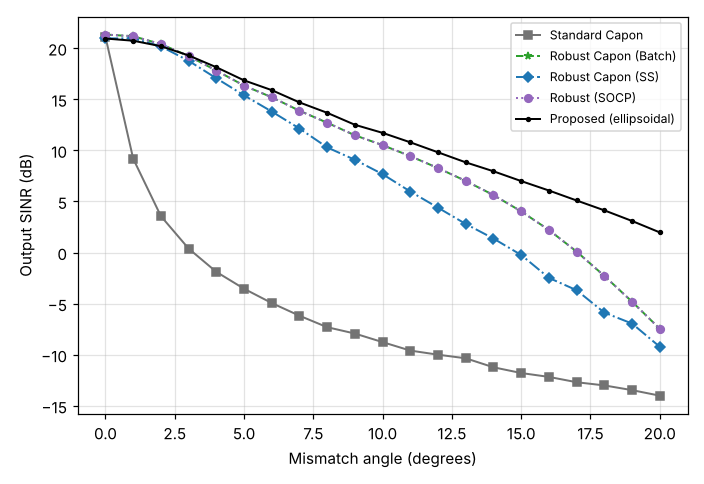

Fig1.16 {
 "Standard Capon": {
  "0": 21.1,
  "5": -3.54,
  "10": -8.77,
  "15": -11.79,
  "20": -14.01
 },
 "Robust Capon (Batch)": {
  "0": 21.33,
  "5": 16.33,
  "10": 10.5,
  "15": 4.02,
  "20": -7.47
 },
 "Robust Capon (SS)": {
  "0": 20.95,
  "5": 15.38,
  "10": 7.67,
  "15": -0.24,
  "20": -9.22
 },
 "Robust (SOCP)": {
  "0": 21.33,
  "5": 16.33,
  "10": 10.5,
  "15": 4.03,
  "20": -7.47
 },
 "Proposed1": {
  "0": 20.94,
  "5": 16.84,
  "10": 11.71,
  "15": 6.99,
  "20": 1.97
 }
}


In [9]:
def fig_1_16():
    """Fig 1.16: SINR vs mismatch angle (noise -15 dB, eps 1)"""
    angs = np.arange(0, 21, 1)
    keep = KEEP_A
    res = {m: np.zeros(len(angs)) for m in keep}
    for i, a in enumerate(angs):
        for r in range(RUNS_SWEEP):
            o = tap_run(900 + 41 * i + r, noise_db=-15, mis=np.deg2rad(a), eps=1.0, delta_socp=socp_delta(1.0, 2.0),
                        alpha=0.008, method='SD', tau=None, final_only=True)
            for m in keep:
                res[m][i] += o[m]['sinr'][-1] / RUNS_SWEEP
    fig, _ = curve_plot({m: db(res[m]) for m in keep}, 'Output SINR (dB)', '', xlabel='Mismatch angle (degrees)', x=angs)
    save(fig, 'Fig1_16_SINR_vs_mismatch')
    RESULTS['Fig1.16'] = {m: dict(zip([int(v) for v in angs[::5]], np.round(db(res[m])[::5], 2).tolist())) for m in keep}


fig_1_16()
import json
for _k in ['Fig1.16']:
    if _k in RESULTS:
        print(_k, json.dumps(RESULTS[_k], indent=1, default=str))

## Part B — IET 2008

Common settings and the WC-parameter plot.

In [10]:
BASE_B = dict(noise_db=0.0, mis_deg=5.0, zeta=1.8, zeta_socp=zeta_socp(1.8), alpha=0.1)


def wc_param_plot(log, name, show_zeta=False):
    L = np.array([[r[0], r[1], r[2], r[3], r[4]] for r in log], float)
    k = np.arange(1, len(L) + 1)
    act = np.array([r[5] != 'inactive' for r in log])
    ttl = ['A', 'B', 'C', r'$\lambda$']
    n = 5 if show_zeta else 4
    fig, axs = plt.subplots(2, 3 if show_zeta else 2, figsize=(9 if show_zeta else 6.4, 4.8))
    axs = axs.ravel()
    for q in range(4):
        y = np.where(act, L[:, q], np.nan)
        axs[q].plot(k, y, 'b-', lw=1, marker='*', markevery=100, ms=5)
        yv = y[2:][np.isfinite(y[2:])]
        if yv.size:                              # scale to snapshots 3..N; the first activation (R ~ I) is off-scale
            lo, hi = yv.min(), yv.max()
            pad = 0.08 * (hi - lo if hi > lo else abs(hi) + 1e-30)
            axs[q].set_ylim(lo - pad, hi + pad)
        if not np.isfinite(y).any():
            axs[q].text(0.5, 0.5, 'no admissible root\n' + r'($\zeta \geq \|\mathbf{a}\|$: infeasible)',
                        ha='center', va='center', transform=axs[q].transAxes, fontsize=9)
            axs[q].set_xlim(1, len(k))
            axs[q].set_yticks([])
        axs[q].set_title(ttl[q])
        axs[q].set_xlabel('Snapshot')
        axs[q].grid(True, alpha=0.35)
        axs[q].ticklabel_format(axis='y', style='sci', scilimits=(-2, 3))
    if show_zeta:
        axs[4].plot(k, L[:, 4], 'k-', lw=1.2)
        axs[4].set_title(r'$\zeta$')
        axs[4].set_xlabel('Snapshot')
        axs[4].grid(True, alpha=0.35)
        axs[5].axis('off')
    save(fig, name)

### Fig. 1.17: WC beamformers, SINR vs snapshot

M = 5, SOI at 0° with SNR 5 dB, presumed 5°; interferers at 30° and 60° (INR 10 dB); noise 0 dB; ζ = 1.8; α = 0.1; 100 runs.

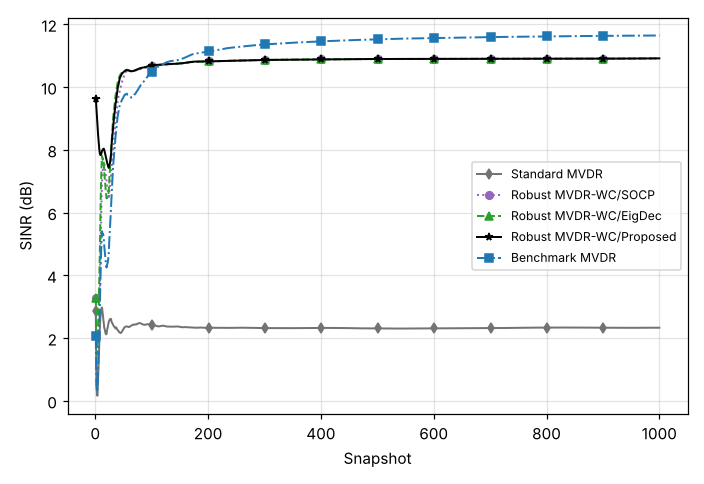

Fig1.17 {
 "Standard MVDR": 2.3288429762284157,
 "Robust MVDR-WC/SOCP": 10.907572544288573,
 "Robust MVDR-WC/EigDec": 10.907803487057992,
 "Robust MVDR-WC/Proposed": 10.907795696846826,
 "Benchmark MVDR": 11.639763048124276
}
Fig1.17_k10 {
 "Standard MVDR": 3.01,
 "Robust MVDR-WC/SOCP": 3.26,
 "Robust MVDR-WC/EigDec": 6.53,
 "Robust MVDR-WC/Proposed": 7.72,
 "Benchmark MVDR": 4.35
}


In [11]:
def fig_1_17():
    """Fig 1.17: SINR vs snapshot"""
    acc, o = iet_mc(RUNS_IET, base_seed=1000, **BASE_B)
    fig, _ = curve_plot({m: db(msmooth(acc[m])) for m in WC_METHODS}, 'SINR (dB)', '')
    save(fig, 'Fig1_17_WC_SINR')
    RESULTS['Fig1.17'] = {m: ss(acc[m]) for m in WC_METHODS}
    RESULTS['Fig1.17_k10'] = {m: round(float(db(acc[m][9])), 2) for m in WC_METHODS}


fig_1_17()
import json
for _k in ['Fig1.17', 'Fig1.17_k10']:
    if _k in RESULTS:
        print(_k, json.dumps(RESULTS[_k], indent=1, default=str))

### Fig. 1.18: steady-state beampatterns (single run)

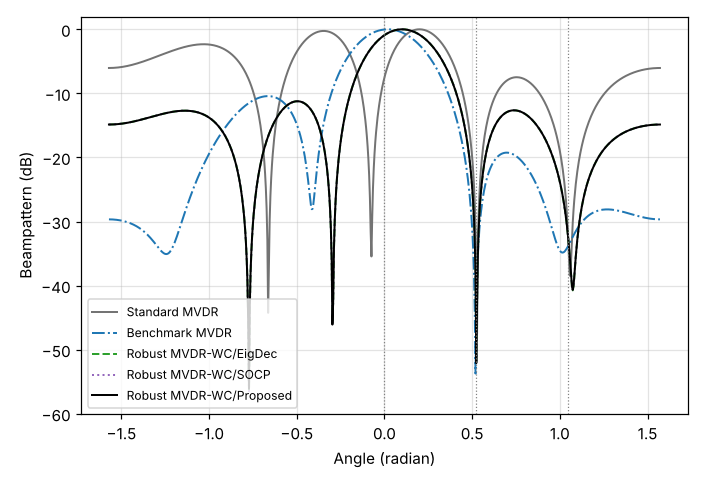

In [12]:
def fig_1_18():
    """Fig 1.18: steady-state beampatterns (one run)"""
    o = iet_run(1000, **BASE_B)
    pattern_plot(o['_w'], 'Fig1_18_WC_beampattern', [0.0, np.pi / 6, np.pi / 3])


fig_1_18()
import json
for _k in []:
    if _k in RESULTS:
        print(_k, json.dumps(RESULTS[_k], indent=1, default=str))

### Fig. 1.19: SINR vs noise power with N = 50 training snapshots

300 runs per point.

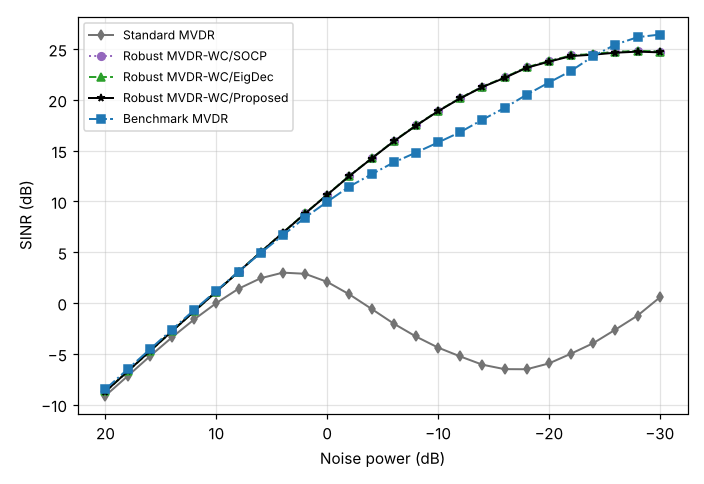

Fig1.19 {
 "Standard MVDR": {
  "20": -9.12,
  "10": -0.01,
  "0": 2.08,
  "-10": -4.39,
  "-20": -5.95,
  "-30": 0.55
 },
 "Robust MVDR-WC/SOCP": {
  "20": -8.71,
  "10": 1.13,
  "0": 10.66,
  "-10": 18.9,
  "-20": 23.8,
  "-30": 24.75
 },
 "Robust MVDR-WC/EigDec": {
  "20": -8.71,
  "10": 1.13,
  "0": 10.66,
  "-10": 18.9,
  "-20": 23.8,
  "-30": 24.75
 },
 "Robust MVDR-WC/Proposed": {
  "20": -8.71,
  "10": 1.12,
  "0": 10.64,
  "-10": 18.87,
  "-20": 23.75,
  "-30": 24.67
 },
 "Benchmark MVDR": {
  "20": -8.48,
  "10": 1.21,
  "0": 9.96,
  "-10": 15.8,
  "-20": 21.7,
  "-30": 26.42
 }
}


In [13]:
def fig_1_19():
    """Fig 1.19: SINR vs noise power, N = 50 snapshots"""
    noise = np.arange(20, -31, -2)
    res = {m: np.zeros(len(noise)) for m in WC_METHODS}
    for i, nd in enumerate(noise):
        for r in range(RUNS_N50):
            o = iet_run(3000 + 101 * i + r, **dict(BASE_B, noise_db=nd, N=50, final_only=True))
            for m in WC_METHODS:
                res[m][i] += o['sinr'][m][-1] / RUNS_N50
    fig, ax = curve_plot({m: db(res[m]) for m in WC_METHODS}, 'SINR (dB)', '', xlabel='Noise power (dB)', x=noise)
    ax.invert_xaxis()
    save(fig, 'Fig1_19_WC_SINR_vs_noise_N50')
    RESULTS['Fig1.19'] = {m: dict(zip([int(v) for v in noise[::5]], np.round(db(res[m])[::5], 2).tolist()))
                          for m in WC_METHODS}


fig_1_19()
import json
for _k in ['Fig1.19']:
    if _k in RESULTS:
        print(_k, json.dumps(RESULTS[_k], indent=1, default=str))

### Figs. 1.20, 1.22, 1.23: WC parameters A, B, C, λ

Single run at ζ = 1.8, 1.2 and 2.4. Points where the WC constraint is inactive (no update needed) are left blank. The y-axes are scaled to snapshots 3–1000; the first activation, computed with R ≈ I, is off-scale. ζ = 2.4 exceeds ‖a‖ = √5 ≈ 2.236, so the problem is infeasible and no admissible root exists.

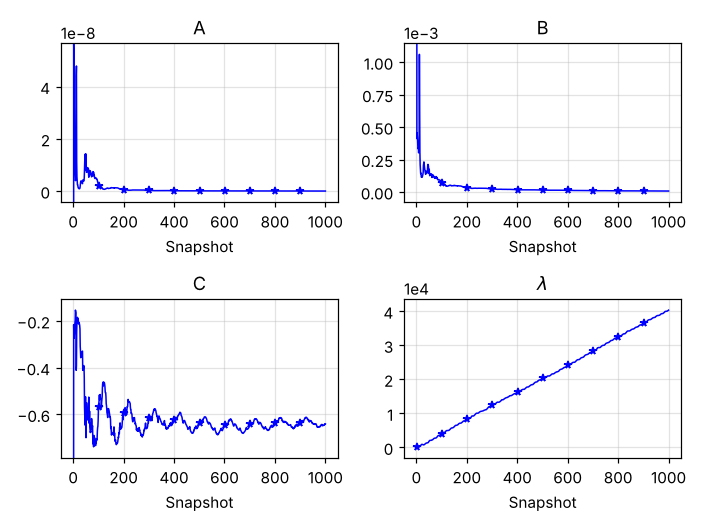

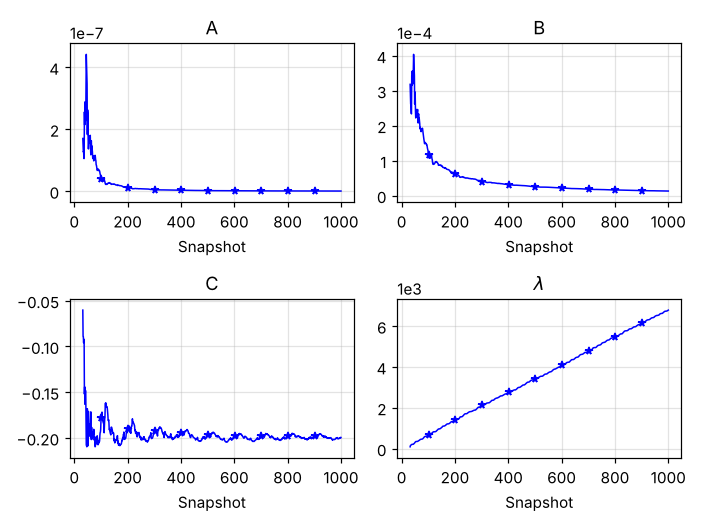

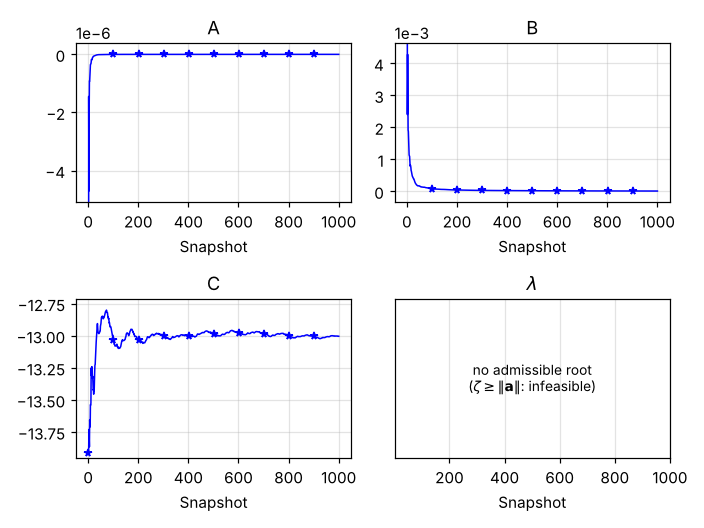

Fig1.20 {
 "status counts": {
  "active": 1000
 },
 "first WC snapshot": 1,
 "final SINR dB": 10.94
}
Fig1.22 {
 "status counts": {
  "inactive": 31,
  "active": 969
 },
 "first WC snapshot": 32,
 "final SINR dB": 10.21
}
Fig1.23 {
 "status counts": {
  "infeasible (zeta >= ||a||)": 1000
 },
 "first WC snapshot": 1,
 "final SINR dB": 0.05
}


In [14]:
def fig_1_20_22_23():
    """Figs 1.20, 1.22, 1.23: WC parameters (single run)"""
    for z, name in [(1.8, 'Fig1_20_WC_params_zeta1p8'), (1.2, 'Fig1_22_WC_params_zeta1p2'),
                    (2.4, 'Fig1_23_WC_params_zeta2p4')]:
        o = iet_run(1000, **dict(BASE_B, zeta=z), methods=['Robust MVDR-WC/Proposed'], log_params=True)
        wc_param_plot(o['log'], name)
        st = {}
        for r in o['log']:
            st[r[5]] = st.get(r[5], 0) + 1
        first = next((i + 1 for i, r in enumerate(o['log']) if r[5] != 'inactive'), None)
        RESULTS['Fig1.' + name[5:7]] = {'status counts': st, 'first WC snapshot': first,
                                                'final SINR dB': round(float(db(o['sinr']['Robust MVDR-WC/Proposed'][-1])), 2)}


fig_1_20_22_23()
import json
for _k in ['Fig1.20', 'Fig1.22', 'Fig1.23']:
    if _k in RESULTS:
        print(_k, json.dumps(RESULTS[_k], indent=1, default=str))

### Fig. 1.21: effect of ζ on the output SINR

100 runs per value of ζ.

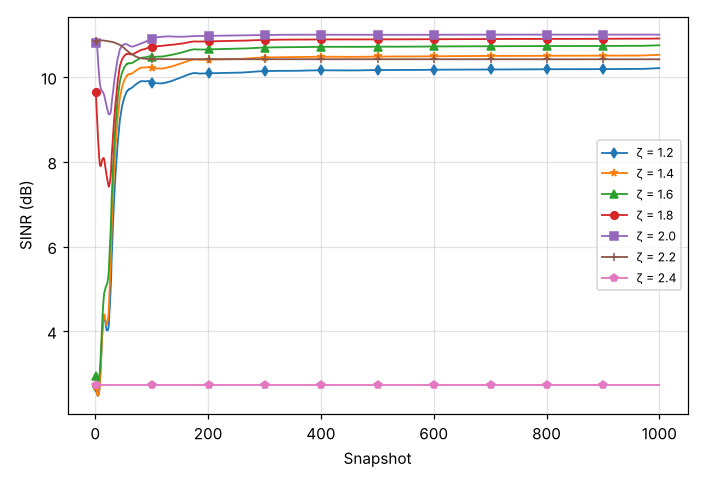

Fig1.21 {
 "\u03b6 = 1.2": 10.188034420169547,
 "\u03b6 = 1.4": 10.505930576213816,
 "\u03b6 = 1.6": 10.735102617189911,
 "\u03b6 = 1.8": 10.903289640180436,
 "\u03b6 = 2.0": 11.003580900459335,
 "\u03b6 = 2.2": 10.419883026164642,
 "\u03b6 = 2.4": 2.741887379361025
}


In [15]:
def fig_1_21():
    """Fig 1.21: effect of zeta"""
    zs = [1.2, 1.4, 1.6, 1.8, 2.0, 2.2, 2.4]
    curves, raw = {}, {}
    for z in zs:
        acc, _ = iet_mc(RUNS_IET, base_seed=4000, **dict(BASE_B, zeta=z), methods=['Robust MVDR-WC/Proposed'])
        raw[f'ζ = {z}'] = acc['Robust MVDR-WC/Proposed']
        curves[f'ζ = {z}'] = db(msmooth(acc['Robust MVDR-WC/Proposed']))
    fig, ax = plt.subplots(figsize=(6.4, 4.4))
    mk = ['d', '*', '^', 'o', 's', '+', 'p']
    for j, (lab, y) in enumerate(curves.items()):
        ax.plot(np.arange(1, len(y) + 1), y, lw=1.2, marker=mk[j], markevery=100, ms=5, label=lab)
    ax.set_xlabel('Snapshot'); ax.set_ylabel('SINR (dB)'); ax.grid(True, alpha=0.35); ax.legend(fontsize=8)
    save(fig, 'Fig1_21_WC_effect_of_zeta')
    RESULTS['Fig1.21'] = {lab: ss(y) for lab, y in raw.items()}


fig_1_21()
import json
for _k in ['Fig1.21']:
    if _k in RESULTS:
        print(_k, json.dumps(RESULTS[_k], indent=1, default=str))

### Figs. 1.24, 1.25: modified algorithm (ζ-reduction)

Start at ζ = 3 (infeasible). Whenever no admissible root exists, ζ is lowered by 0.1 and A, B, C are recomputed (one reduction per snapshot).

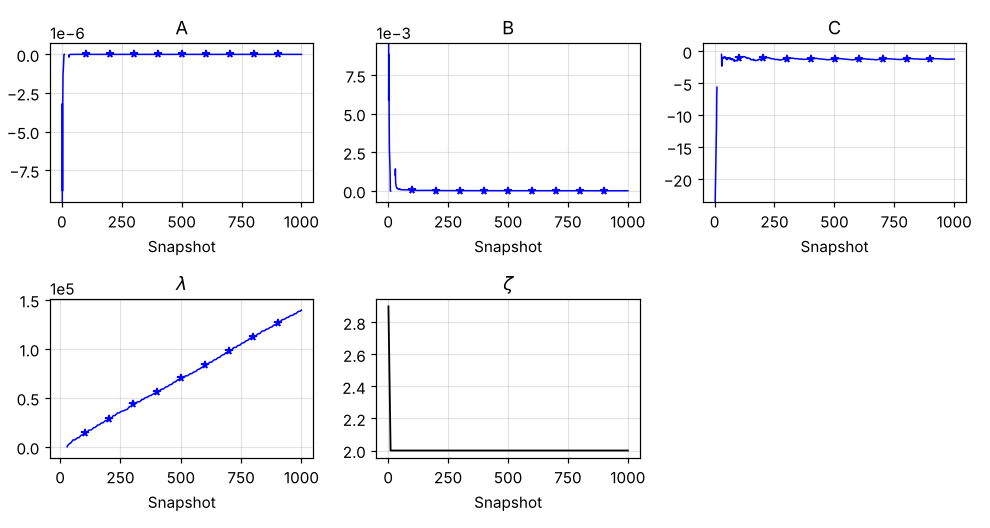

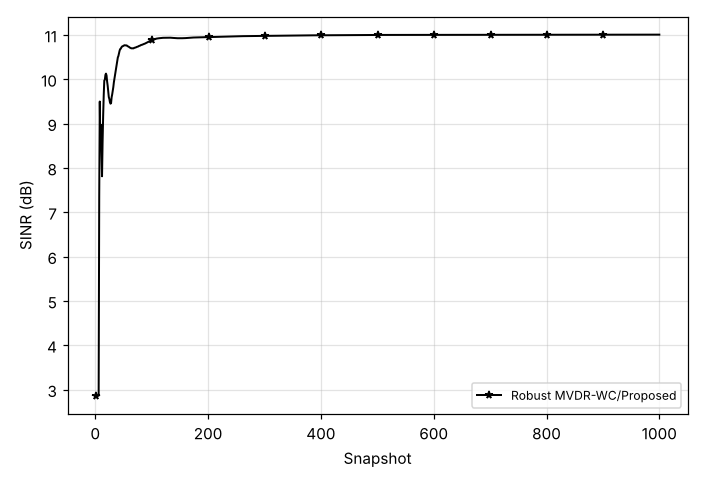

Fig1.24 {
 "zeta start": 3.0,
 "zeta after first snapshot": 2.9,
 "zeta final": 2.0,
 "snapshots until zeta settles": 10
}
Fig1.25 {
 "Robust MVDR-WC/Proposed (modified)": 11.006259525118649
}


In [16]:
def fig_1_24_25():
    """Figs 1.24, 1.25: modified algorithm starting at zeta = 3"""
    o = iet_run(1000, **dict(BASE_B, zeta=3.0), methods=['Robust MVDR-WC/Proposed'], log_params=True, modified=True)
    wc_param_plot(o['log'], 'Fig1_24_WC_params_modified_zeta3', show_zeta=True)
    zt = [r[4] for r in o['log']]
    acc, _ = iet_mc(RUNS_IET, base_seed=1000, **dict(BASE_B, zeta=3.0), methods=['Robust MVDR-WC/Proposed'], modified=True)
    fig, _ = curve_plot({'Robust MVDR-WC/Proposed': db(msmooth(acc['Robust MVDR-WC/Proposed']))}, 'SINR (dB)', '')
    save(fig, 'Fig1_25_WC_SINR_modified')
    RESULTS['Fig1.24'] = {'zeta start': 3.0, 'zeta after first snapshot': zt[0], 'zeta final': round(zt[-1], 2),
                          'snapshots until zeta settles': int(np.argmax(np.array(zt) == zt[-1])) + 1}
    RESULTS['Fig1.25'] = {'Robust MVDR-WC/Proposed (modified)': ss(acc['Robust MVDR-WC/Proposed'])}


fig_1_24_25()
import json
for _k in ['Fig1.24', 'Fig1.25']:
    if _k in RESULTS:
        print(_k, json.dumps(RESULTS[_k], indent=1, default=str))

### Fig. 1.26: small angular spread

Main ray at 0°, two scattered rays at 4° and −3° with amplitude 0.4 (local scattering). The benchmark is the MVDR beamformer with the true composite steering vector.

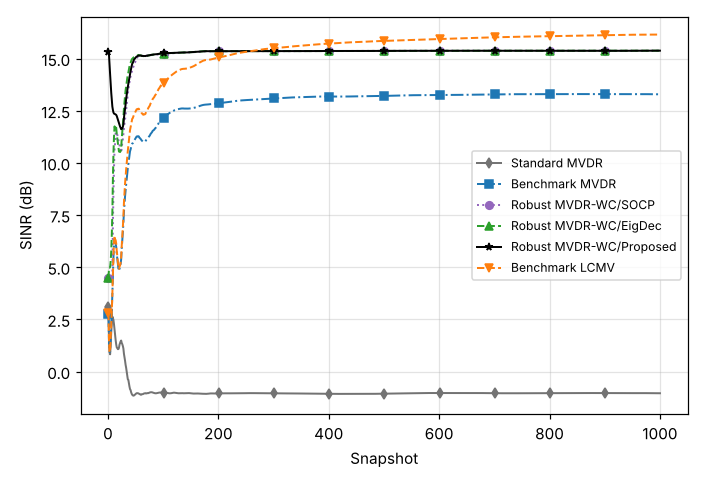

Fig1.26 {
 "Standard MVDR": -1.0348923945725033,
 "Benchmark MVDR": 13.293585750819307,
 "Robust MVDR-WC/SOCP": 15.369858524074107,
 "Robust MVDR-WC/EigDec": 15.369969822652722,
 "Robust MVDR-WC/Proposed": 15.369967647148302,
 "Benchmark LCMV": 16.140535862711737
}


In [17]:
def fig_1_26():
    """Fig 1.26: small angular spread"""
    m26 = ['Standard MVDR', 'Benchmark MVDR', 'Robust MVDR-WC/SOCP', 'Robust MVDR-WC/EigDec',
           'Robust MVDR-WC/Proposed', 'Benchmark LCMV']
    acc, _ = iet_mc(RUNS_IET, base_seed=5000, **BASE_B, methods=m26,
                    multipath=dict(doas=[4.0, -3.0], amp=0.4, random_phase=False, bench='composite'))
    fig, _ = curve_plot({m: db(msmooth(acc[m])) for m in m26}, 'SINR (dB)', '')
    save(fig, 'Fig1_26_WC_small_angular_spread')
    RESULTS['Fig1.26'] = {m: ss(acc[m]) for m in m26}


fig_1_26()
import json
for _k in ['Fig1.26']:
    if _k in RESULTS:
        print(_k, json.dumps(RESULTS[_k], indent=1, default=str))

### Fig. 1.27: large angular spread, MBWC

Rays at 0°, −30° and −80° with amplitude 0.4 and random phases. MBWC LCMV with υ = [1.6, 0.2, 0.2], response vector [1, 0.5, 0.5], α = 0.3.

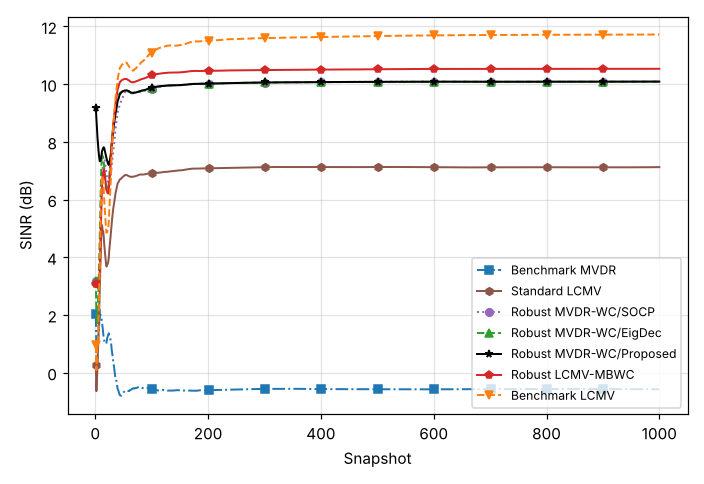

Fig1.27 {
 "Benchmark MVDR": -0.5711972718181292,
 "Standard LCMV": 7.117817896342517,
 "Robust MVDR-WC/SOCP": 10.084637835668104,
 "Robust MVDR-WC/EigDec": 10.084957791279113,
 "Robust MVDR-WC/Proposed": 10.084894938133237,
 "Robust LCMV-MBWC": 10.529138666689615,
 "Benchmark LCMV": 11.71786802308781
}


In [18]:
def fig_1_27():
    """Fig 1.27: large angular spread with MBWC"""
    m27 = ['Benchmark MVDR', 'Standard LCMV', 'Robust MVDR-WC/SOCP', 'Robust MVDR-WC/EigDec',
           'Robust MVDR-WC/Proposed', 'Robust LCMV-MBWC', 'Benchmark LCMV']
    acc, o = iet_mc(RUNS_IET, base_seed=6000, **BASE_B, methods=m27,
                    multipath=dict(doas=[-30.0, -80.0], amp=0.4, random_phase=True),
                    mbwc=dict(ups=[1.6, 0.2, 0.2], ivec=[1.0, 0.5, 0.5], alpha=0.3))
    fig, _ = curve_plot({m: db(msmooth(acc[m])) for m in m27}, 'SINR (dB)', '')
    save(fig, 'Fig1_27_WC_large_angular_spread_MBWC')
    RESULTS['Fig1.27'] = {m: ss(acc[m]) for m in m27}


fig_1_27()
import json
for _k in ['Fig1.27']:
    if _k in RESULTS:
        print(_k, json.dumps(RESULTS[_k], indent=1, default=str))

## Summary

Steady-state SINR (mean of the last 100 snapshots, dB) for the snapshot-domain figures, and the full results file.

In [19]:
import json, pandas as pd
with open(os.path.join(OUT, 'results_summary.json'), 'w') as f:
    json.dump(RESULTS, f, indent=1, default=str)
rows = {k: v for k, v in RESULTS.items() if k in ('Fig1.5', 'Fig1.10', 'Fig1.13', 'Fig1.14', 'Fig1.15',
                                                    'Fig1.17', 'Fig1.26', 'Fig1.27')}
pd.DataFrame(rows).round(2)

,Fig1.5,Fig1.10,Fig1.13,Fig1.14,Fig1.15,Fig1.17,Fig1.26,Fig1.27
Standard Capon,1.10,-13.61,5.99,5.41,10.77,NaN,NaN,NaN
Robust Capon (Batch),19.95,10.29,13.48,3.89,11.31,NaN,NaN,NaN
Robust Capon (SS),17.36,6.47,12.53,3.13,10.36,NaN,NaN,NaN
Robust (SOCP),19.95,10.29,13.43,3.83,11.26,NaN,NaN,NaN
Proposed1,20.39,12.23,15.48,8.11,11.58,NaN,NaN,NaN
Proposed2,20.02,12.21,NaN,NaN,NaN,NaN,NaN,NaN
Standard MVDR,NaN,NaN,NaN,NaN,NaN,2.33,-1.03,NaN
Robust MVDR-WC/SOCP,NaN,NaN,NaN,NaN,NaN,10.91,15.37,10.08
Robust MVDR-WC/EigDec,NaN,NaN,NaN,NaN,NaN,10.91,15.37,10.08
Robust MVDR-WC/Proposed,NaN,NaN,NaN,NaN,NaN,10.91,15.37,10.08
